# Penerapan Visualisasi Data Pemegang Saham BEI
Project ini bertujuan untuk menerapkan teknik visualisasi data menggunakan Python, Pandas, dan Matplotlib pada dataset pemegang saham yang bersumber dari Bursa Efek Indonesia (BEI).

Dataset yang digunakan berisi 500 baris data dengan informasi mengenai kode saham, nama perusahaan, identitas investor, klasifikasi investor, kewarganegaraan, domisili, jumlah kepemilikan saham, dan persentase kepemilikan.

Proses pengerjaan meliputi pembacaan dataset, pemeriksaan struktur data, persiapan data, pengelompokan informasi, serta penyajian hasil analisis dalam bentuk grafik. Visualisasi dibuat untuk membantu memahami distribusi klasifikasi investor, perbandingan investor lokal dan asing, serta kepemilikan saham berdasarkan kode saham dan nama investor.

Melalui project ini, diharapkan data berbentuk tabel dapat disajikan secara visual sehingga informasi di dalamnya lebih mudah dipahami dan dibandingkan.


Sumber Dataset:

Dataset yang digunakan berasal dari Bursa Efek Indonesia (BEI)

Jumlah data: 500 baris

Jumlah kolom: 10 kolom

Format file: Excel (.xlsx)

Link Google Drive: https://docs.google.com/spreadsheets/d/1otWATHNfWh3_rkG_iSq-zASMjYjjxR1_/edit?usp=sharing&ouid=106854584341732448358&rtpof=true&sd=true

##Persiapan Dataset
Pada Bagian ini menjelaskan tahap awal sebelum melakukan visualisasi data. Persiapan meliputi pengimporan library yang dibutuhkan, menghubungkan Google Drive, dan membaca dataset yang akan dianalisis.

### Import Library
Pada tahap ini mengimpor library yang dibutuhkan dalam proses visualisasi data. Pandas digunakan untuk membaca dan mengolah dataset, sedangkan Matplotlib digunakan untuk membuat dan mengatur tampilan grafik

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

### Mount Google Drive
Ini dilakukan untuk menghubungkan Google Colab dengan Google Drive agar dataset yang tersimpan di dalamnya dapat diakses

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


### Membaca Dataset
Selanjutnya  membaca dataset dalam format Excel menggunakan Pandas. Data yang telah dibaca akan disimpan dalam DataFrame agar dapat diperiksa, diolah, dan digunakan dalam proses visualisasi

In [ ]:
file_path = '/content/drive/MyDrive/Colab Notebooks/dataset_BEI_pemegang_saham_1persen.xlsx'

df = pd.read_excel(
    file_path,
    sheet_name='Dataset 500 Baris'
)

print("Dataset berhasil dibaca.")

Dataset berhasil dibaca.


##Pemeriksaan Awal Dataset
Bagian ini untuk memahami struktur dan kondisi dataset sebelum dilakukan pengolahan lebih lanjut. Pemeriksaan dilakukan terhadap informasi dataset, nilai yang kosong, dan tipe data pada setiap kolom

###Informasi Dataset
tahap ini dlakukan untuk mengetahui jumlah baris dan kolom, nama kolom, serta gambaran awal isi dataset. Informasi ini membantu memahami struktur data yang akan digunakan dalam proses visualisasi

In [ ]:
print("Ukuran dataset:", df.shape)

print("\nNama kolom:")
print(df.columns.tolist())

print("\nInformasi dataset:")
df.info()

print("\nLima data pertama:")
display(df.head())

Ukuran dataset: (500, 10)

Nama kolom:
['DATE', 'SHARE_CODE', 'ISSUER_NAME', 'INVESTOR_NAME', 'INVESTOR_CLASSIFICATION', 'LOCAL_FOREIGN', 'NATIONALITY', 'DOMICILE', 'TOTAL_HOLDING_SHARES', 'PERCENTAGE']

Informasi dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   DATE                     500 non-null    datetime64[ns]
 1   SHARE_CODE               500 non-null    object        
 2   ISSUER_NAME              500 non-null    object        
 3   INVESTOR_NAME            500 non-null    object        
 4   INVESTOR_CLASSIFICATION  500 non-null    object        
 5   LOCAL_FOREIGN            500 non-null    object        
 6   NATIONALITY              500 non-null    object        
 7   DOMICILE                 500 non-null    object        
 8   TOTAL_HOLDING_SHARES     500 non-null    int64         
 

,DATE,SHARE_CODE,ISSUER_NAME,INVESTOR_NAME,INVESTOR_CLASSIFICATION,LOCAL_FOREIGN,NATIONALITY,DOMICILE,TOTAL_HOLDING_SHARES,PERCENTAGE
0,2026-07-31,ABDA,ASURANSI BINA DANA ARTA Tbk,OONA INDONESIA PTE LTD,Insurance,F,Tidak diketahui,SINGAPORE,538561304,86.75
1,2026-07-31,ABMM,ABM INVESTAMA Tbk,PT TIARA MARGA TRAKINDO,Corporate,L,Tidak diketahui,INDONESIA,1474573133,53.56
2,2026-07-31,AGAR,ASIA SEJAHTERA MINA Tbk,PT. BENGAWAN TIMUR LAJU,Corporate,L,Tidak diketahui,INDONESIA,43000000,4.30
3,2026-07-31,AKKU,ANUGERAH KAGUM KARYA UTAMA Tbk,PT LOKASI EMAS INDONESIA PROPERTI,Firm,L,Tidak diketahui,INDONESIA,126925800,1.97
4,2026-07-31,AKPI,ARGHA KARYA PRIMA INDUSTRY Tbk,PT. TIARA INTIMAHKOTA,Corporate,L,Tidak diketahui,INDONESIA,221072988,36.11


###Pemeriksaan Missing Value
Melakukan pemeriksaan terhadap nilai kosong atau missing value pada setiap kolom. Pemeriksaan diperlukan untuk memastikan kelengkapan data sehingga tidak mengganggu proses pengelompokan maupun pembuatan grafik

In [ ]:
print("Jumlah missing value setiap kolom:")
print(df.isnull().sum())

print("\nTotal missing value:")
print(df.isnull().sum().sum())

Jumlah missing value setiap kolom:
DATE                       0
SHARE_CODE                 0
ISSUER_NAME                0
INVESTOR_NAME              0
INVESTOR_CLASSIFICATION    0
LOCAL_FOREIGN              0
NATIONALITY                0
DOMICILE                   0
TOTAL_HOLDING_SHARES       0
PERCENTAGE                 0
dtype: int64

Total missing value:
0


### Pemeriksaan Tipe Data
Memeriksa tipe data pada setiap kolom, seperti teks, tanggal, dan numerik. Pemeriksaan diperlukan agar setiap kolom dapat digunakan sesuai fungsinya, terutama kolom jumlah kepemilikan saham dan persentase kepemilikan yang akan digunakan dalam perhitungan

In [ ]:
print("Tipe data setiap kolom:")
print(df.dtypes)

Tipe data setiap kolom:
DATE                       datetime64[ns]
SHARE_CODE                         object
ISSUER_NAME                        object
INVESTOR_NAME                      object
INVESTOR_CLASSIFICATION            object
LOCAL_FOREIGN                      object
NATIONALITY                        object
DOMICILE                           object
TOTAL_HOLDING_SHARES                int64
PERCENTAGE                        float64
dtype: object


##Persiapan dan Pengolahan Data
Bagian ini menjelaskan proses menyiapkan data sesuai kebutuhan visualisasi. Pengolahan dilakukan dengan memilih kolom yang relevan serta mengelompokkan data untuk memperoleh informasi yang lebih mudah dianalisis

### Memilih Kolom yang digunakan
Memilih kolom yang diperlukan untuk setiap visualisasi yang dipilih dari dataset utama. Pemilihan kolom bertujuan menyederhanakan proses analisis agar hanya menggunakan data yang berkaitan dengan informasi yang ingin ditampilkan

In [ ]:
kolom_visualisasi = [
    'SHARE_CODE',
    'INVESTOR_NAME',
    'INVESTOR_CLASSIFICATION',
    'LOCAL_FOREIGN',
    'TOTAL_HOLDING_SHARES',
    'PERCENTAGE'
]
data_visualisasi = df[kolom_visualisasi].copy()
display(data_visualisasi.head())

,SHARE_CODE,INVESTOR_NAME,INVESTOR_CLASSIFICATION,LOCAL_FOREIGN,TOTAL_HOLDING_SHARES,PERCENTAGE
0,ABDA,OONA INDONESIA PTE LTD,Insurance,F,538561304,86.75
1,ABMM,PT TIARA MARGA TRAKINDO,Corporate,L,1474573133,53.56
2,AGAR,PT. BENGAWAN TIMUR LAJU,Corporate,L,43000000,4.30
3,AKKU,PT LOKASI EMAS INDONESIA PROPERTI,Firm,L,126925800,1.97
4,AKPI,PT. TIARA INTIMAHKOTA,Corporate,L,221072988,36.11


### Menambahkan Data Agregat
Pada tahap ini yaitu mengelompokkan data berdasarkan kategori tertentu dan melakukan perhitungan yang diperlukan. Contohnya, menghitung jumlah investor pada setiap klasifikasi, membandingkan jumlah investor lokal dan asing, serta menjumlahkan kepemilikan saham berdasarkan kode saham

In [ ]:
# Menghitung jumlah investor berdasarkan klasifikasi
jumlah_klasifikasi = (
    data_visualisasi['INVESTOR_CLASSIFICATION']
    .value_counts()
)

# Menghitung jumlah investor berdasarkan status lokal/asing
jumlah_lokal_asing = (
    data_visualisasi['LOCAL_FOREIGN']
    .value_counts()
)

# Menjumlahkan kepemilikan saham berdasarkan kode saham
kepemilikan_saham = (
    data_visualisasi
    .groupby('SHARE_CODE')['TOTAL_HOLDING_SHARES']
    .sum()
    .sort_values(ascending=False)
)

print("Jumlah berdasarkan klasifikasi investor:")
display(jumlah_klasifikasi)

print("Jumlah berdasarkan status lokal dan asing:")
display(jumlah_lokal_asing)

print("Total kepemilikan berdasarkan kode saham:")
display(kepemilikan_saham.head(10))

Jumlah berdasarkan klasifikasi investor:


,count
INVESTOR_CLASSIFICATION,
Individual,250
Corporate,150
Private Bank,13
Securities Company,12
Private Equity,10
Mutual Funds,10
Firm,10
Investment Advisors,6
Insurance,6


Jumlah berdasarkan status lokal dan asing:


,count
LOCAL_FOREIGN,
L,413
F,87


Total kepemilikan berdasarkan kode saham:


,TOTAL_HOLDING_SHARES
SHARE_CODE,
BELI,104009002820
BNII,37962479550
NETV,36419523872
WIKA,35928785753
MPPA,26100859264
VKTR,19403380077
AMRT,18186464285
KPIG,14024614600
CLEO,13469824800


##Penerapan Visualisasi Data
Pada bagian ini mennyajikan data ke dalam bentuk grafik. Visualisasi dibuat agar informasi dalam dataset lebih mudah dibaca, dibandingkan, dan dipahami.

###Visualisasi 1 - Distribusi Klasifikasi Investor
Visualisasi ini digunakan untuk menunjukkan jumlah investor berdasarkan klasifikasinya. Grafik membantu melihat kategori investor yang memiliki jumlah terbanyak dalam dataset

####Mengelompokkan Data Investor
Data dikelompokkan berdasarkan klasifikasi investor untuk memperoleh jumlah data pada setiap kategori. Hasil pengelompokan ini digunakan sebagai sumber data untuk membuat grafik batang

In [ ]:
jumlah_klasifikasi = (
    df['INVESTOR_CLASSIFICATION']
    .value_counts()
    .sort_values(ascending=False)
)

display(jumlah_klasifikasi)

,count
INVESTOR_CLASSIFICATION,
Individual,250
Corporate,150
Private Bank,13
Securities Company,12
Private Equity,10
Mutual Funds,10
Firm,10
Investment Advisors,6
Insurance,6


####Membuat Grafik Batang
Grafik batang dibuat untuk menampilkan jumlah investor pada setiap klasifikasi. Pada tahap ini, grafik ditampilkan dalam bentuk dasar sebelum ditambahkan pengaturan dan elemen visual lainnya

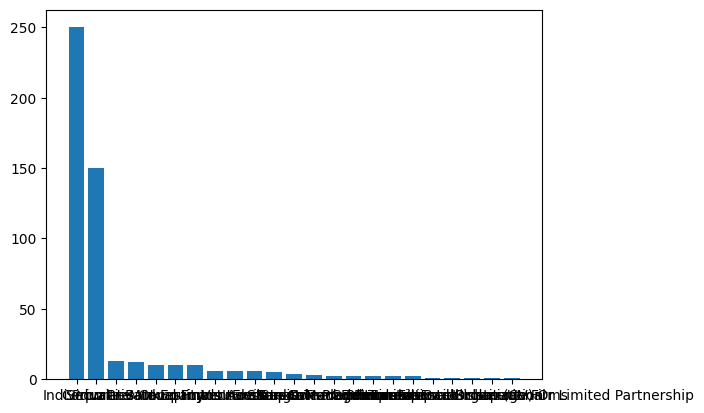

In [ ]:
plt.bar(
    jumlah_klasifikasi.index,
    jumlah_klasifikasi.values
)

plt.show()

####Anatomi Figure dan Axes
Selanjutnya dilakukan pengenalan terhadap anatomi grafik menggunakan Matplotlib. Figure merupakan keseluruhan area gambar, sedangkan Axes merupakan area tempat grafik ditampilkan. Penggunaan fig, ax = plt.subplots() memungkinkan pengaturan grafik dilakukan melalui objek Figure dan Axes secara terpisah.

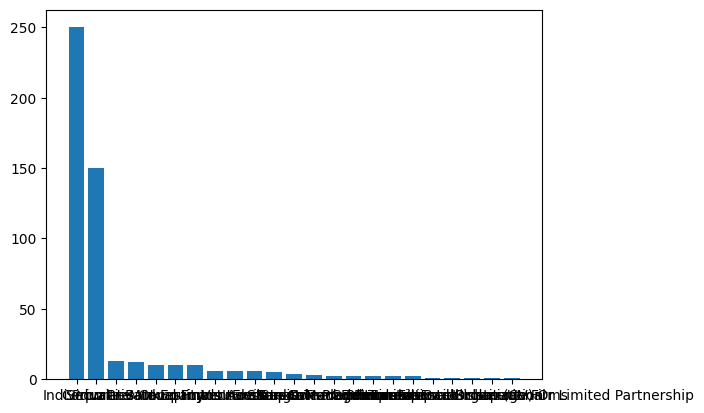

In [ ]:
fig, ax = plt.subplots()

ax.bar(
    jumlah_klasifikasi.index,
    jumlah_klasifikasi.values
)

plt.show()


####Mengatur Figure Size
Ukuran grafik diatur menggunakan parameter figsize agar area visualisasi lebih luas dan mudah dibaca. Pengaturan ukuran gambar juga memberikan ruang yang cukup untuk menampilkan nama klasifikasi investor

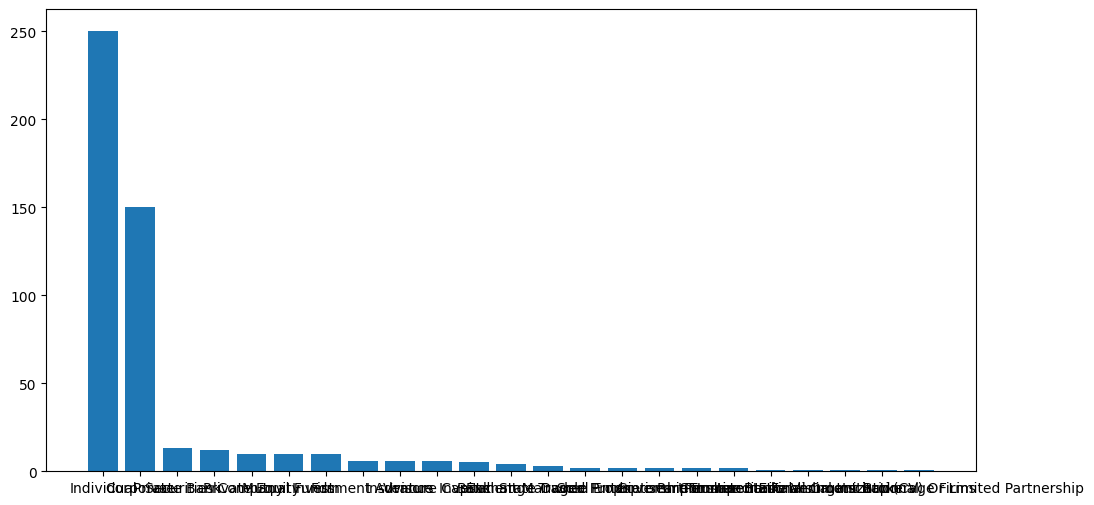

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    jumlah_klasifikasi.index,
    jumlah_klasifikasi.values
)

plt.show()


####Menambahkan Title dan Axis Labels
Menambahkan Judul grafik dan label sumbu untuk menjelaskan informasi yang disajikan. Judul menunjukkan topik visualisasi, sedangkan sumbu X menunjukkan klasifikasi investor dan sumbu Y menunjukkan jumlah data.

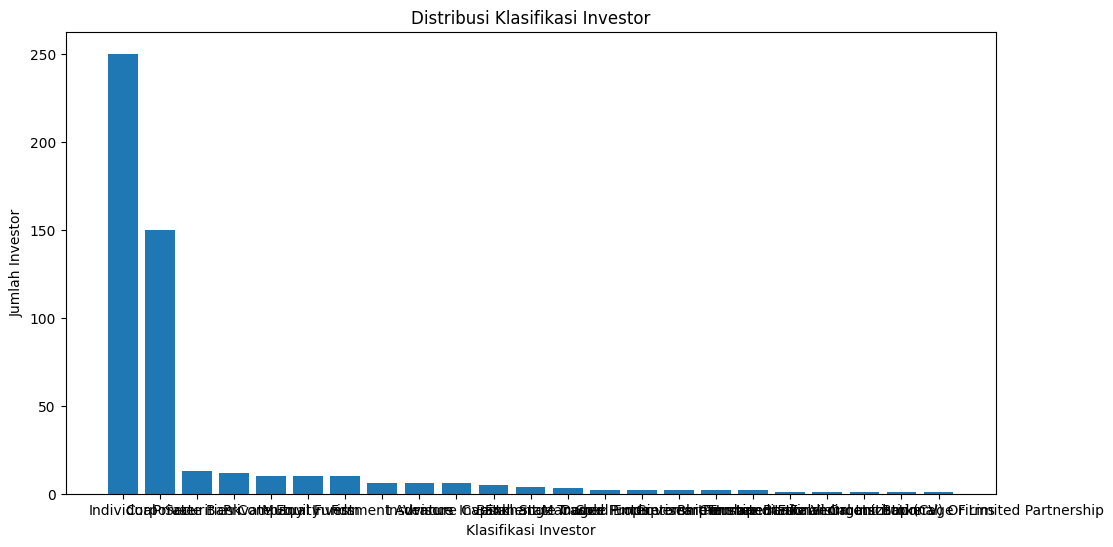

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    jumlah_klasifikasi.index,
    jumlah_klasifikasi.values
)

ax.set_title('Distribusi Klasifikasi Investor')
ax.set_xlabel('Klasifikasi Investor')
ax.set_ylabel('Jumlah Investor')

plt.show()


####Kustomisasi Grafik
Kustomisasi grafik dilakukan untuk meningkatkan keterbacaan melalui pengaturan warna batang, ukuran teks, kemiringan label, dan garis bantu

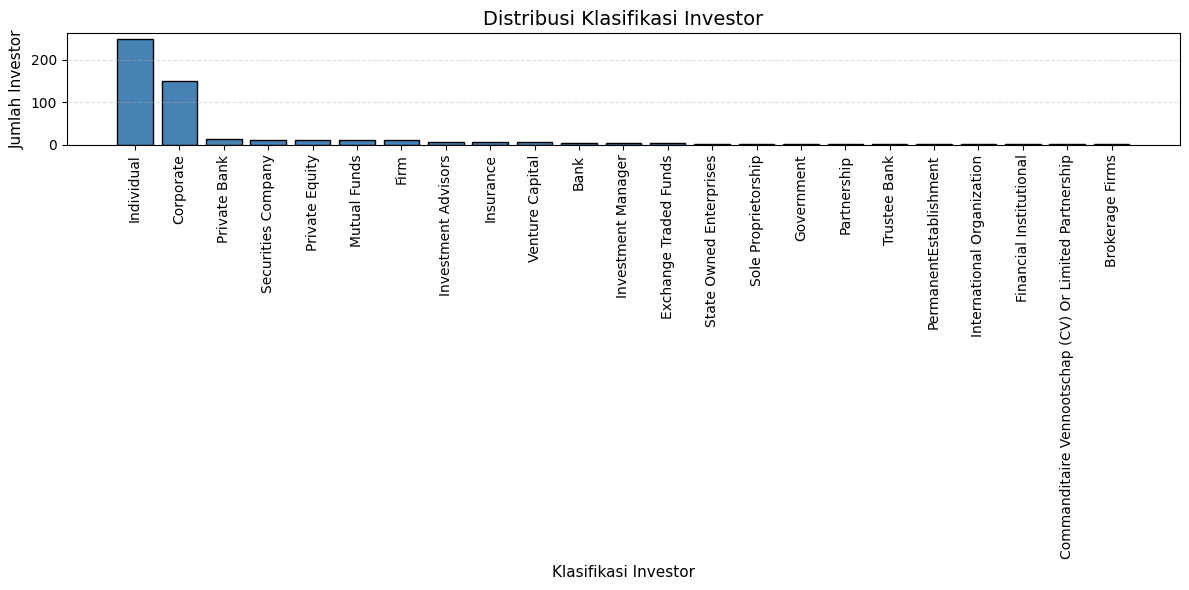

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.bar(
    jumlah_klasifikasi.index,
    jumlah_klasifikasi.values,
    color='steelblue',
    edgecolor='black'
)

ax.set_title(
    'Distribusi Klasifikasi Investor',
    fontsize=14
)
ax.set_xlabel('Klasifikasi Investor', fontsize=11)
ax.set_ylabel('Jumlah Investor', fontsize=11)

ax.tick_params(axis='x', rotation=90)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


####Menambahkan Label dan Anotasi Data
Label nilai ditambahkan untuk menunjukkan jumlah data pada setiap batang. Anotasi digunakan untuk menyoroti kategori dengan jumlah data terbesar sehingga informasi utama dapat diketahui dengan lebih mudah.

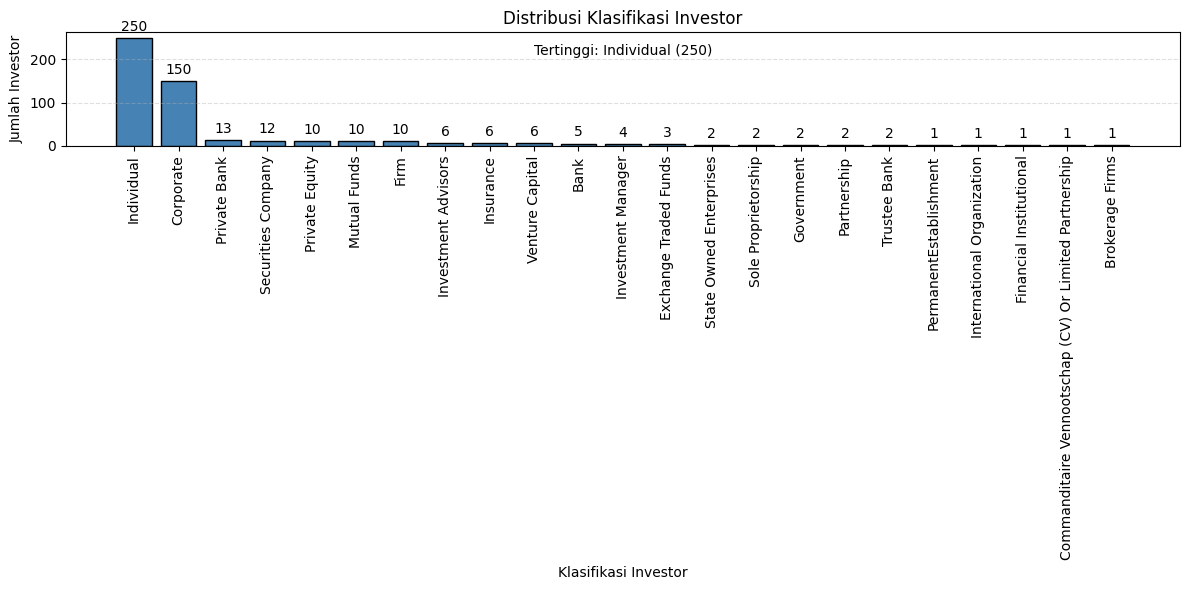

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

bars = ax.bar(
    jumlah_klasifikasi.index,
    jumlah_klasifikasi.values,
    color='steelblue',
    edgecolor='black'
)

ax.set_title('Distribusi Klasifikasi Investor')
ax.set_xlabel('Klasifikasi Investor')
ax.set_ylabel('Jumlah Investor')

ax.tick_params(axis='x', rotation=90)
ax.bar_label(bars, padding=3)

kategori_terbesar = jumlah_klasifikasi.idxmax()
nilai_terbesar = jumlah_klasifikasi.max()

ax.annotate(
    f'Tertinggi: {kategori_terbesar} ({nilai_terbesar})',
    xy=(0.5, 0.8),
    xycoords='axes fraction',
    ha='center'
)

ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


###Visualisasi 2 - Perbandingan Investor Lokal dan Asing
Visualisasi ini digunakan untuk membandingkan jumlah data investor lokal dan asing berdasarkan kolom LOCAL_FOREIGN. Grafik batang membantu memperlihatkan perbedaan jumlah data antara kedua kategori tersebut

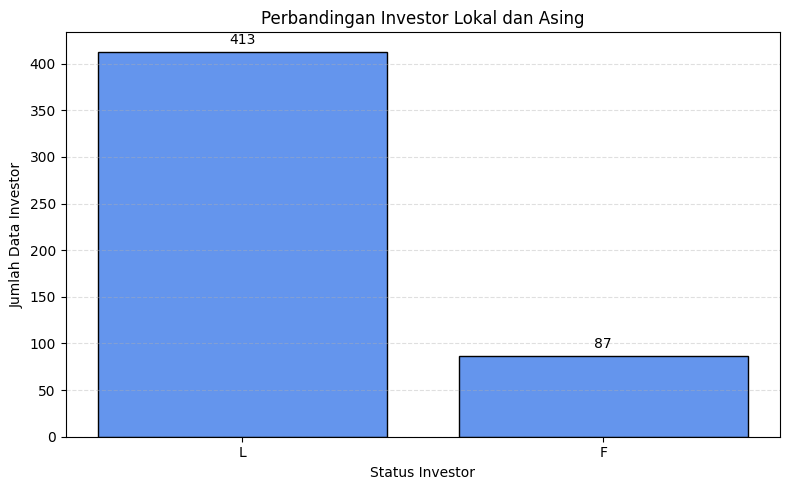

In [ ]:
jumlah_lokal_asing = df['LOCAL_FOREIGN'].value_counts()

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    jumlah_lokal_asing.index,
    jumlah_lokal_asing.values,
    color='cornflowerblue',
    edgecolor='black'
)

ax.set_title('Perbandingan Investor Lokal dan Asing')
ax.set_xlabel('Status Investor')
ax.set_ylabel('Jumlah Data Investor')

ax.bar_label(bars, padding=3)
ax.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


### Visualisasi 3 - Kode Saham Berdasarkan Total Kepemilikan
Visualisasi ini untuk menampilkan 10 kode saham dengan total kepemilikan saham terbesar. Data dikelompokkan berdasarkan kode saham, kemudian jumlah kepemilikan saham dijumlahkan dan diurutkan dari nilai terbesar

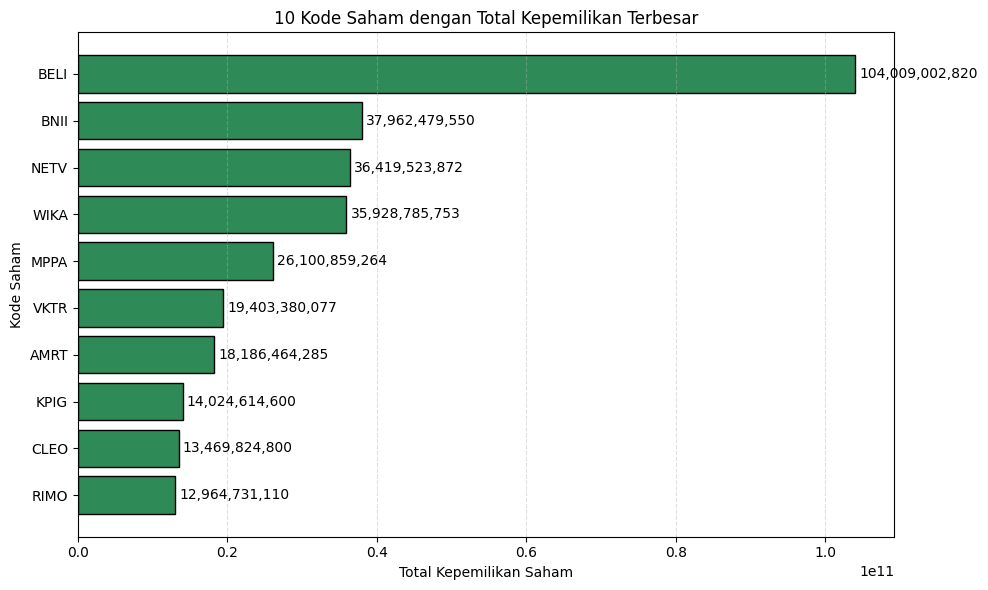

In [ ]:
kepemilikan_saham = (
    df.groupby('SHARE_CODE')['TOTAL_HOLDING_SHARES']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    kepemilikan_saham.index,
    kepemilikan_saham.values,
    color='seagreen',
    edgecolor='black'
)

ax.set_title('10 Kode Saham dengan Total Kepemilikan Terbesar')
ax.set_xlabel('Total Kepemilikan Saham')
ax.set_ylabel('Kode Saham')

ax.bar_label(bars, padding=3, fmt='{:,.0f}')
ax.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


###Visualisasi 4 - Investor Berdasarkan Persentase Kepemilikan
Visualisasi ini  untuk menampilkan 10 investor dengan persentase kepemilikan terbesar berdasarkan data yang tersedia. Data dikelompokkan berdasarkan nama investor, kemudian diurutkan berdasarkan persentase tertinggi. Jika nama investor muncul beberapa kali, nilai yang digunakan adalah persentase terbesar yang tercatat untuk investor tersebut

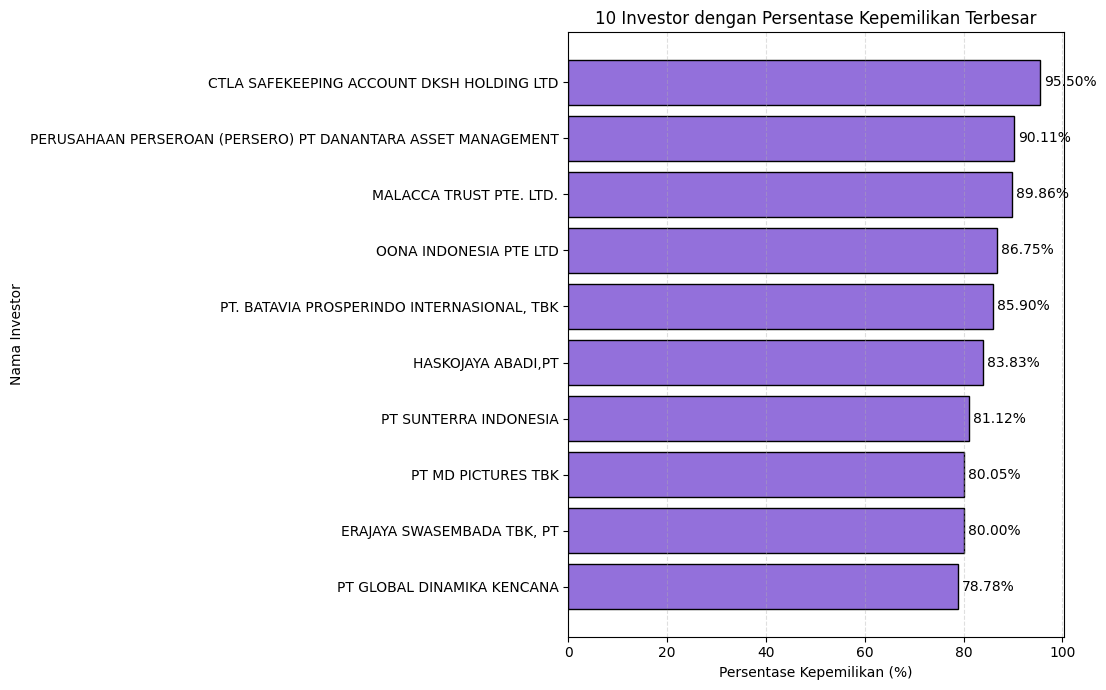

In [ ]:
persentase_investor = (
    df.groupby('INVESTOR_NAME')['PERCENTAGE']
    .max()
    .sort_values(ascending=False)
    .head(10)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    persentase_investor.index,
    persentase_investor.values,
    color='mediumpurple',
    edgecolor='black'
)

ax.set_title('10 Investor dengan Persentase Kepemilikan Terbesar')
ax.set_xlabel('Persentase Kepemilikan (%)')
ax.set_ylabel('Nama Investor')

ax.bar_label(bars, padding=3, fmt='%.2f%%')
ax.grid(axis='x', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.show()


##Kesimpulan
Berdasarkan hasil pengolahan dan visualisasi data pemegang saham Bursa Efek Indonesia (BEI), kategori investor Individual memiliki jumlah data terbanyak, yaitu 250 data, diikuti Corporate sebanyak 150 data. Berdasarkan status investor, data lokal berjumlah 413, sedangkan data asing berjumlah 87. Pada visualisasi total kepemilikan saham, kode saham BELI memiliki nilai terbesar sebesar 104.009.002.820 saham. Sementara itu, CTLA SAFEKEEPING ACCOUNT DKSH HOLDING LTD memiliki persentase kepemilikan tertinggi di antara 10 investor yang ditampilkan, yaitu sebesar 95,50%. Dengan demikian, visualisasi data dapat mempermudah pemahaman terhadap distribusi investor dan informasi kepemilikan saham berdasarkan dataset yang dianalisis.